# astream과 응답 스트림

**이 노트북에서 할 일**

1. 노드가 답을 낱말마다 진행 값으로 적는 줄을 읽습니다.
2. 비동기 메서드 `astream`과 `async for`로 스트림 사건을 하나씩 받아 이어 붙입니다.
3. 모드 목록에 `updates`를 더해, 노드 끝 사건이 진행 값보다 뒤에 오는지 실험합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

그래프를 같은 노트북 안에서 바로 부릅니다.
서버 프로그램을 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 사건이 온 차례와 개수만 봅니다.
앞 챕터에서 배운 함수 둘은 도구 파일 `serve_tools.py`에서 가져옵니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~4절을 읽고, 5절 실험의 가설을 함께 세웁니다.
5절의 두 실행과 6절은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 입력 messages에 질문 하나에서 초록 상자 노드 answer 낱말마다 쓰기 함수로 진행 값을 적음으로 이어집니다. 이어서 회색 상자 astream 모드 custom, 파란 상자 async for로 사건을 하나씩 받음, 노란 상자 스트림 사건 여섯 모두 칸 token 하나를 지납니다. 마지막으로 파란 상자 받을 때마다 글을 뒤에 이어 붙임과 노란 상자 이어 붙인 글 끝에 공백 하나 공백을 지우면 ainvoke 답과 같음 True로 이어지는 그림](attachment:04-1-진행-값에서-이어-붙인-글까지.png)

위에서 아래로 읽습니다.
초록 상자 둘은 우리가 넣은 입력과 실습 폴더의 노드이고, 회색 상자는 라이브러리 메서드입니다.
파란 상자 둘은 노트북에서 우리가 쓴 줄이고, 노란 상자 둘은 노트북 3·4절의 출력입니다.
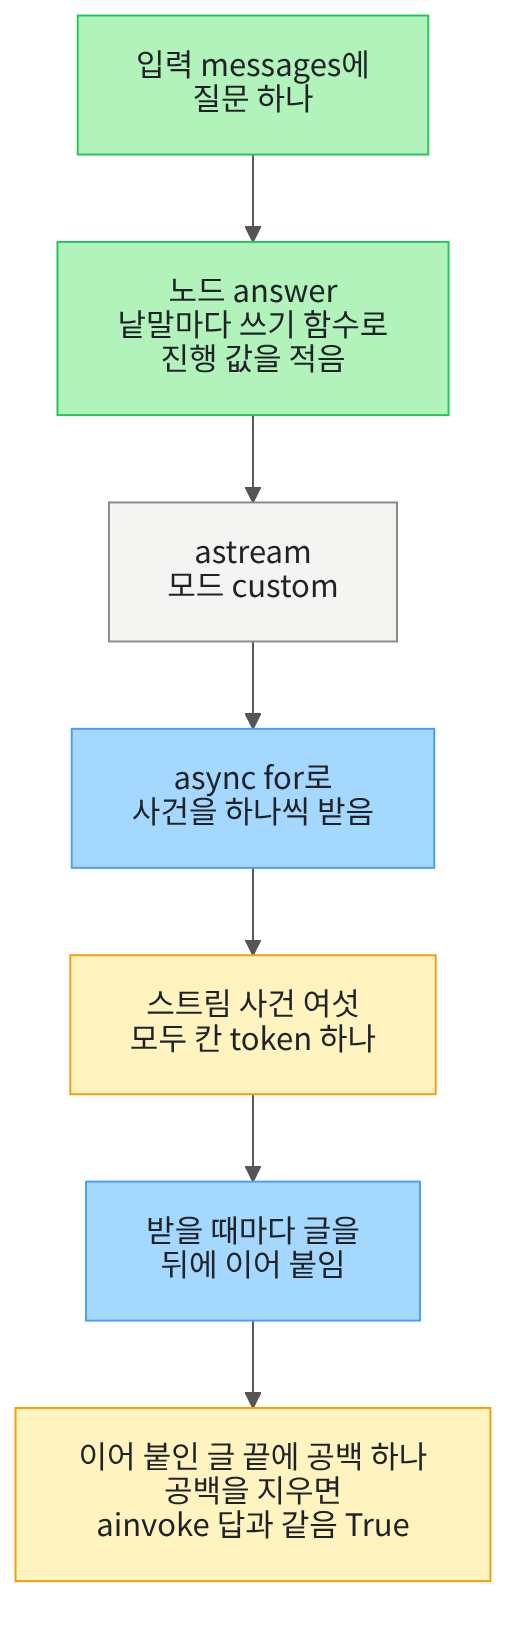

## 1. 준비

03절에서는 처리 함수가 그래프를 await와 `ainvoke`로 불러, 끝난 결과를 한 번에 받았습니다.
이 절은 같은 그래프를 비동기 메서드 `astream`으로 불러, 노드가 적은 값을 하나씩 받습니다.
제목의 astream은 Ch 25에서 배운 메서드 `stream`의 비동기 판입니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.
fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `langgraph: 1.2.11`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 03절과 같은 목록입니다.
이 절은 모델 객체를 만들지 않아, API 키를 확인하는 셀도 없습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `inspect`는 03절에서 함수의 소스 글을 꺼낼 때 쓴 모듈입니다.
마지막 가져오기 줄은 Ch 25에서 배운 함수 둘을 도구 파일에서 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·inspect는 Python에 들어 있는 모듈입니다)
import os
import inspect
# Ch 25 01·02절에서 배운 함수 둘은 도구 파일에서 가져옵니다
from serve_tools import mode_order, positions_of

print("가져온 이름:", "inspect")
print("도구 파일에서 가져온 함수:", "mode_order, positions_of")

가져온 이름: inspect
도구 파일에서 가져온 함수: mode_order, positions_of


**결과 읽기** — 출력 줄 `도구 파일에서 가져온 함수: mode_order, positions_of`가 보입니다.
함수 `positions_of`는 Ch 25 01절, `mode_order`는 Ch 25 02절에서 배웠습니다.
두 함수 모두 (모드 이름, 자료) 짝의 목록을 받습니다.
Ch 25 도구 파일 `stream_tools.py`의 같은 이름 함수를, 주석과 본문 그대로 옮겼습니다.

앞에서 배운 함수는 `serve_tools.py`에 모아 두었습니다.
파일을 열면 코드를 볼 수 있습니다.
노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.
교재 출력을 만든 실행 도구는 이 폴더를 따로 알려 주어, 다른 자리에서 시작해도 가져오기가 되었습니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.
실습 폴더 맨 위에서 연 커널은 이 안내를 보기 전에, 앞 셀의 도구 파일 가져오기에서 먼저 멈춥니다.

다음 셀은 03절처럼 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
그래프 파일 `agent.py`에서 에이전트 그래프 `agent`와 노드 함수 `answer_node`를 가져옵니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 그래프 파일에서 그래프와 노드 함수를 가져옵니다
os.chdir(lab_path)
from agent_service.agent import agent, answer_node
print("가져온 그래프의 종류:", type(agent).__name__)
print("그래프의 노드 이름:", list(agent.nodes))

가져온 그래프의 종류: CompiledStateGraph
그래프의 노드 이름: ['__start__', 'answer']


**결과 읽기** — 출력 줄 `가져온 그래프의 종류: CompiledStateGraph`가 보입니다.
노드 이름은 `['__start__', 'answer']`이고, 답을 만드는 노드는 `answer` 하나입니다.
03절에서 본 것처럼 이 노드는 비동기 노드이고, 모델을 쓰지 않습니다.

## 2. 노드가 진행 값을 적는 줄

Ch 25 01절에서는 노드 안에서 `get_stream_writer()`로 쓰기 함수를 꺼내 진행 값을 보냈습니다.
실습 그래프의 노드도 같은 방법으로 진행 값을 적습니다.
다음 셀은 노드 함수 `answer_node`의 소스 글을 그대로 출력합니다.

In [5]:
# 노드 함수 answer_node를 소스 글 그대로 출력합니다(inspect.getsource는 03절에서 썼습니다)
node_source = inspect.getsource(answer_node)
print("노드 함수 answer_node의 소스:")
print(node_source)

노드 함수 answer_node의 소스:
async def answer_node(state: AgentState) -> dict[str, object]:
    question = state["messages"][-1]
    answer = _compose_answer(question)
    try:
        writer = get_stream_writer()
    except RuntimeError:
        writer = None
    for piece in answer.split():
        await asyncio.sleep(0)
        if writer is not None:
            writer({"token": piece + " "})
    return {"answer": answer}



**결과 읽기** — 라벨 줄 아래에 정의 줄부터 `return` 줄까지 열두 줄이 있습니다.
셋째 줄의 함수 `_compose_answer`가 답 글 전체를 먼저 만듭니다.
그다음 줄 `writer = get_stream_writer()`가 쓰기 함수를 꺼냅니다.
그래프 밖에서 노드 함수를 바로 부르면 이 줄이 오류 `RuntimeError`를 내서, `try`로 받아 `None`으로 둡니다.

반복 줄 `for piece in answer.split():`은 답 글을 공백으로 나눈 낱말마다 돕니다.
낱말마다 `await asyncio.sleep(0)`으로 한 번 쉬고, `writer({"token": piece + " "})`로 진행 값을 적습니다.
Python 문서는 0초 쉬기를 다른 작업에 차례를 넘기는 방법이라고 적습니다.
그래서 진행 값 하나는 칸 `token` 하나를 가진 딕셔너리이고, 낱말 뒤에 공백이 붙습니다.

다음 셀은 03절과 같은 질문으로 입력을 만듭니다.

In [6]:
# 03절과 같은 질문으로, 그래프에 넣을 입력을 만듭니다
question_input = {"messages": ["반납 기한을 알려 주세요"]}
print("입력:", question_input)

입력: {'messages': ['반납 기한을 알려 주세요']}


**결과 읽기** — 출력 줄 `입력: {'messages': ['반납 기한을 알려 주세요']}`가 보입니다.
03절 3절의 입력과 같은 모양, 같은 질문입니다.

## 3. astream과 async for

03절 4절에서는 이 그래프를 동기 메서드 `stream`으로 불러 오류 `TypeError`를 받았습니다.
그 오류 글은 비동기로 부르는 메서드로 `ainvoke`와 `astream`을 적었습니다.
메서드 `astream`은 `stream`의 비동기 판이고, 인자 `stream_mode`도 같습니다.
다음 셀은 모드 `custom`으로 `astream`을 부르기만 하고, 받은 값의 종류를 봅니다.

In [7]:
# astream을 모드 custom으로 부르기만 하고, 받은 값의 종류를 봅니다
# astream은 입력과 모드를 받아, 스트림 사건을 하나씩 꺼낼 수 있는 객체를 내놓습니다
stream_obj = agent.astream(question_input, stream_mode="custom")
print("부르기만 해서 받은 값의 종류:", type(stream_obj).__name__)

부르기만 해서 받은 값의 종류: async_generator


**결과 읽기** — 출력 줄 `부르기만 해서 받은 값의 종류: async_generator`가 보입니다.
받은 값은 비동기 제너레이터(async generator)이고, 이 줄에서는 사건을 하나도 받지 않았습니다.
Ch 6 04절에서 메서드 `stream()`이 준 객체 종류는 `generator`였습니다.
비동기 제너레이터는 그 제너레이터의 비동기 판으로, 값을 하나 꺼낼 때마다 await로 기다려 받습니다.

값을 꺼내는 반복이 비동기 반복(async for)입니다.
보통 반복처럼 값을 하나씩 꺼내 본문을 실행하되, 꺼낼 때마다 다음 값을 await로 기다립니다.
역에 칸이 하나 들어올 때마다 기다렸다가 짐을 내리는 일과 같습니다.
다음 셀은 `async for`로 사건을 꺼내, 받을 때마다 출력하고 목록에 담습니다.
셀 맨 위의 `async for`는 셀 맨 위 await처럼 노트북 도구(IPython)의 기능입니다.

In [8]:
# async for로 사건을 하나씩 꺼내, 받을 때마다 출력하고 목록에 담습니다
events = []
async for event in stream_obj:
    print("받은 스트림 사건:", event)
    events.append(event)
print("받은 사건 수:", len(events))

받은 스트림 사건: {'token': '질문을 '}
받은 스트림 사건: {'token': '확인했습니다: '}
받은 스트림 사건: {'token': '반납 '}
받은 스트림 사건: {'token': '기한을 '}
받은 스트림 사건: {'token': '알려 '}
받은 스트림 사건: {'token': '주세요 '}
받은 사건 수: 6


**결과 읽기** — 라벨 `받은 스트림 사건:`이 붙은 줄이 여섯이고, 출력 줄 `받은 사건 수: 6`이 보입니다.
첫 사건은 `{'token': '질문을 '}`이고, 마지막 사건은 `{'token': '주세요 '}`입니다.
사건마다 낱말 하나와 그 뒤 공백 하나가 칸 `token`에 들어 있습니다.
Ch 25 01절에서 본 진행 값이, 비동기 판에서도 스트림 사건으로 하나씩 왔습니다.

다음 셀은 첫 사건의 종류와 키를 출력해 모양을 확인합니다.

In [9]:
# 첫 사건의 종류와 키, 칸 token의 값을 봅니다
first_event = events[0]
print("첫 사건의 종류:", type(first_event).__name__)
print("첫 사건의 키:", list(first_event))
print("첫 사건의 칸 token:", first_event["token"])

첫 사건의 종류: dict
첫 사건의 키: ['token']
첫 사건의 칸 token: 질문을 


**결과 읽기** — 출력 줄 `첫 사건의 종류: dict`와 `첫 사건의 키: ['token']`이 보입니다.
모드를 하나만 고르면 사건은 자료 그대로이고, 모드 이름이 붙지 않습니다.
Ch 25 01절에서 모드를 목록으로 골랐을 때의 (모드 이름, 자료) 짝과 다른 모양입니다.
칸 `token`의 값 `질문을 ` 뒤에도 공백이 하나 있습니다.

Ch 6 04절에서는 끝까지 꺼낸 제너레이터가 비어 있었습니다.
다음 셀은 이미 끝까지 꺼낸 `stream_obj`에서 사건을 한 번 더 꺼내 봅니다.

In [10]:
# 이미 끝까지 꺼낸 stream_obj에서 사건을 한 번 더 꺼내 봅니다
again_events = []
async for event in stream_obj:
    again_events.append(event)
print("다시 꺼낸 사건 수:", len(again_events))

다시 꺼낸 사건 수: 0


**결과 읽기** — 출력 줄 `다시 꺼낸 사건 수: 0`이 보입니다.
한 번 끝까지 꺼낸 비동기 제너레이터는 비어 있어, 사건을 하나도 받지 않았습니다.
사건을 다시 받으려면 메서드 `astream`을 새로 불러야 합니다.

## 4. 받을 때마다 이어 붙이기

화면에 답을 앞 낱말부터 보이려면, 사건을 받을 때마다 글을 뒤에 붙입니다.
다음 셀은 `astream`을 새로 불러, 칸 `token`의 글을 받을 때마다 이어 붙이고 출력합니다.
반복 줄에서 메서드를 바로 부르는 모양은 6절에서 볼 앱 파일과 같습니다.

In [11]:
# astream을 새로 불러, 사건을 받을 때마다 칸 token의 글을 뒤에 이어 붙이고 출력합니다
shown_text = ""
async for event in agent.astream(question_input, stream_mode="custom"):
    shown_text = shown_text + event["token"]
    print("지금까지 이어 붙인 글:", shown_text)

지금까지 이어 붙인 글: 질문을 
지금까지 이어 붙인 글: 질문을 확인했습니다: 
지금까지 이어 붙인 글: 질문을 확인했습니다: 반납 
지금까지 이어 붙인 글: 질문을 확인했습니다: 반납 기한을 
지금까지 이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 
지금까지 이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 주세요 


**결과 읽기** — 라벨 `지금까지 이어 붙인 글:`이 붙은 줄이 여섯입니다.
첫 줄은 `지금까지 이어 붙인 글: 질문을`이고, 줄마다 낱말이 하나씩 늘어납니다.
마지막 줄은 `지금까지 이어 붙인 글: 질문을 확인했습니다: 반납 기한을 알려 주세요`입니다.
사건을 받을 때마다 반복 본문이 한 번씩 실행되어, 받은 차례대로 글이 길어졌습니다.

다음 셀은 이어 붙인 글의 끝 글자를 보고, 03절처럼 `ainvoke`로 받은 답과 견줍니다.

In [12]:
# 이어 붙인 글의 끝 글자를 보고, 03절처럼 ainvoke로 받은 답과 견줍니다
print("끝 글자가 공백인가:", shown_text.endswith(" "))
result = await agent.ainvoke(question_input)
print("ainvoke 결과의 칸 answer:", result["answer"])
print("그대로 견주면 같은가:", shown_text == result["answer"])
# strip()은 글의 앞뒤 공백을 지운 새 글을 내놓습니다
print("앞뒤 공백을 지우고 견주면 같은가:", shown_text.strip() == result["answer"])

끝 글자가 공백인가: True
ainvoke 결과의 칸 answer: 질문을 확인했습니다: 반납 기한을 알려 주세요
그대로 견주면 같은가: False
앞뒤 공백을 지우고 견주면 같은가: True


**결과 읽기** — 출력 줄 `끝 글자가 공백인가: True`와 `그대로 견주면 같은가: False`가 보입니다.
출력 줄 `앞뒤 공백을 지우고 견주면 같은가: True`도 보입니다.
이어 붙인 글은 끝에 공백이 하나 남아, 그대로는 `ainvoke`의 답과 다릅니다.
메서드 `strip()`으로 앞뒤 공백을 지우자 같은 글이 되었습니다.

다음 셀은 사건 수가 어디서 정해지는지, 답의 낱말 수와 견줍니다.

In [13]:
# 답을 공백으로 나눈 낱말 수와, 3절에서 받은 사건 수를 견줍니다
answer_words = result["answer"].split()
print("답의 낱말:", answer_words)
print("답의 낱말 수:", len(answer_words))
print("받은 사건 수:", len(events))
print("두 수가 같은가:", len(answer_words) == len(events))

답의 낱말: ['질문을', '확인했습니다:', '반납', '기한을', '알려', '주세요']
답의 낱말 수: 6
받은 사건 수: 6
두 수가 같은가: True


**결과 읽기** — 출력 줄 `답의 낱말 수: 6`과 `받은 사건 수: 6`, `두 수가 같은가: True`가 보입니다.
라벨 `답의 낱말:` 줄에는 정해 둔 말의 두 낱말과 질문의 네 낱말이 있습니다.
2절에서 읽은 대로, 노드가 답을 공백으로 나눈 낱말마다 진행 값을 하나씩 적었기 때문입니다.
노드 코드로 보면 질문의 낱말 수가 바뀔 때 사건 수도 바뀌고, 이번에는 다른 질문을 넣지 않았습니다.

## 5. 실험: 모드 목록에 updates를 더하기

Ch 25 01절에서는 동기 `stream`으로 모드를 목록으로 골라, 사건이 나온 자리를 봤습니다.
그때 노드가 보낸 진행 값은 그 노드의 갱신(`updates`)보다 먼저 나왔습니다.
이 실험은 같은 차례가 비동기 판 `astream`에서도 나오는지 봅니다.
바꿀 값은 인자 `stream_mode` 하나이고, 그래프와 입력은 그대로 둡니다.

**가설** — 실행 1은 모드 `custom` 하나, 실행 2는 모드 목록 `["custom", "updates"]`입니다.
실행 2에서는 노드가 끝난 뒤의 갱신 사건이 하나 더해져, 사건이 일곱이 될 것입니다.
더해진 사건은 진행 값 여섯보다 뒤, 맨 끝 자리에 올 것입니다.
진행 값 여섯과 이어 붙인 글은 두 실행에서 같을 것입니다.

두 실행에 쓸 함수 둘을 먼저 정의합니다.
다음 셀은 4절에서 셀로 적은 이어 붙이기를 함수로 묶습니다.

In [14]:
# 진행 값 목록을 받아, 칸 token의 글을 차례대로 이어 붙인 글을 내놓습니다
def join_tokens(stream_values):
    joined = ""
    for value in stream_values:
        joined = joined + value["token"]
    return joined

**결과 읽기** — 정의 셀이라 출력이 없습니다.
진행 값 목록을 받아, 칸 `token`의 글을 차례대로 이어 붙인 글을 내놓습니다.
앞뒤 공백은 지우지 않아, 4절의 글처럼 끝에 공백이 남습니다.

다음 셀은 그래프를 `astream`으로 한 번 실행하며, 받은 사건을 목록에 모으는 함수를 정의합니다.
Ch 25 01절 함수 `collect_events`와 같은 일을 `async for`로 하고, 인자 `config`는 받지 않습니다.
함수 안에서 `async for`를 쓰므로 정의 줄은 `async def`이고, 부를 때는 await를 붙입니다.

In [15]:
# 그래프를 astream으로 한 번 실행하며 받은 사건을 차례대로 목록에 모아 내놓습니다
async def collect_events_async(graph_to_run, graph_input, modes):
    collected = []
    # stream_mode에 목록을 주면, 사건 하나가 (모드 이름, 자료) 짝으로 나옵니다
    async for event in graph_to_run.astream(graph_input, stream_mode=modes):
        collected.append(event)
    return collected

**결과 읽기** — 정의 셀이라 출력이 없습니다.
인자 `modes`에 모드 이름 하나를 주면 자료가, 목록을 주면 (모드 이름, 자료) 짝이 모입니다.

**실행 1** — 다음 셀은 모드 `custom` 하나로 사건을 모읍니다.
실행 전에 예상해 봅니다.
사건은 몇 개이고, 이어 붙인 글은 4절과 같을까요?

In [16]:
# 실행 1: 모드 custom 하나로 사건을 모읍니다
run1_events = await collect_events_async(agent, question_input, "custom")
print("사건 수:", len(run1_events))
print("첫 사건:", run1_events[0])
print("마지막 사건:", run1_events[-1])
print("이어 붙인 글이 4절과 같은가:", join_tokens(run1_events) == shown_text)

사건 수: 6
첫 사건: {'token': '질문을 '}
마지막 사건: {'token': '주세요 '}
이어 붙인 글이 4절과 같은가: True


**결과 읽기** — 출력 줄 `사건 수: 6`과 `이어 붙인 글이 4절과 같은가: True`가 보입니다.
첫 사건은 `{'token': '질문을 '}`, 마지막 사건은 `{'token': '주세요 '}`로 3절과 같습니다.
실행 1의 사건은 모두 진행 값입니다.

**실행 2** — 다음 셀은 값 하나만 바꿔, 모드 목록 `["custom", "updates"]`로 사건을 모읍니다.
실행 전에 예상해 봅니다.
사건 수와 사건의 모양은 어떻게 바뀔까요?

In [17]:
# 실행 2: 값 하나만 바꿔, 모드 목록 custom·updates로 사건을 모읍니다
run2_events = await collect_events_async(agent, question_input, ["custom", "updates"])
print("사건 수:", len(run2_events))
first_pair = run2_events[0]
print("첫 사건의 종류와 길이:", type(first_pair).__name__, len(first_pair))
print("첫 사건:", first_pair)
print("마지막 사건:", run2_events[-1])

사건 수: 7
첫 사건의 종류와 길이: tuple 2
첫 사건: ('custom', {'token': '질문을 '})
마지막 사건: ('updates', {'answer': {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}})


**결과 읽기** — 출력 줄 `사건 수: 7`과 `첫 사건의 종류와 길이: tuple 2`가 보입니다.
첫 사건은 `('custom', {'token': '질문을 '})`로, 모드 이름과 자료의 짝입니다.
마지막 사건은 `('updates', {'answer': {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}})`입니다.
가설대로 사건이 하나 늘었고, 첫 사건과 마지막 사건 모두 짝입니다.

다음 셀은 일곱 사건을 받은 차례대로 한 줄씩 출력합니다.
사건 하나에서 모드 이름은 `event[0]`, 자료는 `event[1]`로 꺼냅니다.

In [18]:
# 실행 2의 사건을 받은 차례대로, 자리·모드 이름·자료를 한 줄씩 출력합니다
print("자리 | 모드 이름 | 자료")
for index in range(len(run2_events)):
    event = run2_events[index]
    # 사건 하나는 (모드 이름, 자료) 짝이라, [0]이 모드 이름이고 [1]이 자료입니다
    print(index + 1, "|", event[0], "|", event[1])

자리 | 모드 이름 | 자료
1 | custom | {'token': '질문을 '}
2 | custom | {'token': '확인했습니다: '}
3 | custom | {'token': '반납 '}
4 | custom | {'token': '기한을 '}
5 | custom | {'token': '알려 '}
6 | custom | {'token': '주세요 '}
7 | updates | {'answer': {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}}


**결과 읽기** — 라벨 줄 아래 일곱 줄 가운데 첫 줄은 `1 | custom | {'token': '질문을 '}`입니다.
자리 1부터 6까지는 모두 `custom`이고, 마지막 줄은 `7 | updates | {'answer': {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}}`입니다.
진행 값 여섯이 차례대로 온 뒤에, 노드의 갱신이 한 번 왔습니다.

다음 셀은 Ch 25의 함수 둘로 이 차례를 목록으로 받아 봅니다.
함수 `mode_order`는 모드가 바뀐 차례를, `positions_of`는 한 모드의 사건이 나온 자리를 내놓습니다.

In [19]:
# 도구 파일의 함수 둘로, 모드 차례와 모드마다 나온 자리를 봅니다
print("모드 차례:", mode_order(run2_events))
print("custom 나온 자리:", positions_of(run2_events, "custom"))
print("updates 나온 자리:", positions_of(run2_events, "updates"))

모드 차례: ['custom', 'updates']
custom 나온 자리: [1, 2, 3, 4, 5, 6]
updates 나온 자리: [7]


**결과 읽기** — 출력 줄 `모드 차례: ['custom', 'updates']`가 보입니다.
출력 줄 `custom 나온 자리: [1, 2, 3, 4, 5, 6]`과 `updates 나온 자리: [7]`도 보입니다.
모드 `updates`의 사건은 일곱 사건 가운데 맨 끝 자리 7에 왔습니다.
가설대로, 노드가 끝난 뒤의 갱신은 진행 값 여섯보다 뒤였습니다.

다음 셀은 실행 2에서 모드 `custom`의 자료만 모아 이어 붙이고, 실행 1의 글과 견줍니다.

In [20]:
# 실행 2에서 모드 custom의 자료만 모아 이어 붙이고, 실행 1의 글과 견줍니다
custom_values = []
for event in run2_events:
    if event[0] == "custom":
        custom_values.append(event[1])
print("모은 진행 값 수:", len(custom_values))
print("이어 붙인 글이 실행 1과 같은가:", join_tokens(custom_values) == join_tokens(run1_events))

모은 진행 값 수: 6
이어 붙인 글이 실행 1과 같은가: True


**결과 읽기** — 출력 줄 `모은 진행 값 수: 6`과 `이어 붙인 글이 실행 1과 같은가: True`가 보입니다.
모드 `updates`를 더해도, 진행 값의 수와 글은 바뀌지 않았습니다.

다음 셀은 마지막 사건인 `updates`의 자료를 꺼내, 노드가 낸 갱신을 봅니다.

In [21]:
# 실행 2의 마지막 사건인 updates의 자료에서, 노드가 낸 갱신을 봅니다
update_data = run2_events[-1][1]
print("updates 자료의 키:", list(update_data))
print("노드 answer가 낸 갱신:", update_data["answer"])
print("칸 answer가 ainvoke 답과 같은가:", update_data["answer"]["answer"] == result["answer"])

updates 자료의 키: ['answer']
노드 answer가 낸 갱신: {'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}
칸 answer가 ainvoke 답과 같은가: True


**결과 읽기** — 출력 줄 `updates 자료의 키: ['answer']`가 보입니다.
키 `answer`는 노드 이름이고, 그 값 `{'answer': '질문을 확인했습니다: 반납 기한을 알려 주세요'}`가 노드가 낸 갱신입니다.
출력 줄 `칸 answer가 ainvoke 답과 같은가: True`도 보입니다.
노드는 진행 값 여섯을 모두 적은 뒤에 칸 `answer`를 내며 끝났고, 그 갱신이 마지막 사건이었습니다.

다음 셀은 두 실행을 한 표로 모읍니다.

In [22]:
# 두 실행의 사건 수·진행 값 수·사건의 종류·updates 자리를 한 표로 모읍니다
print("견준 것 | 실행 1 | 실행 2")
print("모드 | custom | custom, updates")
print("사건 수 |", len(run1_events), "|", len(run2_events))
print("진행 값 수 |", len(run1_events), "|", len(custom_values))
print("사건의 종류 |", type(run1_events[0]).__name__, "|", type(first_pair).__name__)
print("updates 나온 자리 | 없음 |", positions_of(run2_events, "updates"))

견준 것 | 실행 1 | 실행 2
모드 | custom | custom, updates
사건 수 | 6 | 7
진행 값 수 | 6 | 6
사건의 종류 | dict | tuple
updates 나온 자리 | 없음 | [7]


**결과 읽기** — 라벨 줄 아래 다섯 줄이 두 실행을 견줍니다.
사건 수는 `사건 수 | 6 | 7`, 사건의 종류는 `사건의 종류 | dict | tuple`입니다.
진행 값 수는 두 실행 모두 여섯이고, 마지막 줄은 `updates 나온 자리 | 없음 | [7]`입니다.

**결론** — 바꾼 값은 인자 `stream_mode` 하나였습니다.
모드 목록에 `updates`를 더하자 사건이 여섯에서 일곱으로 늘고, 모두 (모드 이름, 자료) 짝이 되었습니다.
진행 값 여섯은 자리 1~6에 그대로 왔고, 노드 끝 갱신은 맨 끝 자리 7에 왔습니다.
그래서 받는 쪽이 첫 진행 값을 받은 때에는, 노드 끝 사건을 아직 받지 않은 상태입니다.
이 노트북은 걸린 시간을 재지 않았고, 사건이 온 차례만 확인했습니다.

## 6. 앱 파일에서 astream을 부르는 자리

실습 앱 파일도 처리 함수 안에서 `astream`을 부릅니다.
다음 셀은 앱 파일을 글로 읽어, `astream`을 부르는 줄과 모드를 적은 줄만 줄 번호와 함께 출력합니다.

In [23]:
# 앱 파일을 글로 읽어, astream을 부르는 줄과 모드를 적은 줄만 줄 번호와 함께 출력합니다
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_text = app_file.read()
app_lines = app_text.splitlines()
print("줄 번호 | 줄")
for index in range(len(app_lines)):
    line = app_lines[index]
    if "astream(" in line or "stream_mode=" in line:
        print(index + 1, "|", line.strip())

줄 번호 | 줄
110 | async for chunk in runtime.astream(
111 | {"messages": [body.question]}, stream_mode="custom"
134 | async for message, metadata in runtime.astream(
136 | stream_mode="messages",


**결과 읽기** — 라벨 줄 아래에 네 줄이 있습니다.
첫 두 줄은 `110 | async for chunk in runtime.astream(`와 `111 | {"messages": [body.question]}, stream_mode="custom"`입니다.
처리 함수 `chat_stream`이 이 절과 같은 모드 `custom`으로 `astream`을 부르는 자리입니다.
나머지 두 줄(134·136행)은 모드 `messages`로 부르는 처리 함수 `live_chat_stream`의 줄입니다.

처리 함수 `chat_stream`은 받은 진행 값을 서버 응답으로 보내며, 05절에서 봅니다.
모드 `messages`는 모델이 쓴 글을 받는 모드로, 모델을 부르는 09절에서 씁니다.
두 처리 함수 모두 몸통에서 `astream`을 부르므로, 요청이 올 때마다 새로 부릅니다.

## 정리

1. 비동기 메서드 `astream`은 비동기 제너레이터를 내놓았고, `async for`로 모드 `custom`의 스트림 사건 여섯을 받았습니다.
2. 칸 `token`의 글을 받을 때마다 이어 붙이자 끝에 공백이 하나 남았고, 공백을 지우면 `ainvoke`의 답과 같았습니다.
3. 모드 목록에 `updates`를 더하자 사건이 일곱이 되었고, 노드 끝 갱신은 진행 값 여섯 뒤 자리 7에 왔습니다.

05절에서는 처리 함수 `chat_stream`이 이 진행 값을 SSE 응답으로 보내는 모양을 봅니다.